# Kelompok HHH - Cleaning dan EDA Dataset (UTS PBA 2026/2027)
**Anggota:** Dani Setiawan (240712771), Isidorus Ambar Wicaksono (240712775), Johannes Calvin (240712781)

**Dataset:** No. 8 - Indonesian Google Play Review, e-commerce app (Blibli).

Notebook ini berisi: (1) analisis awal dataset, (2) cleaning yang tercatat langkah demi langkah, (3) pemilihan sampel anotasi, dan (4) EDA sebelum anotasi.
Semua path bersifat relatif terhadap folder proyek (`project_uts/notebook/`), dan notebook dapat dijalankan ulang dari awal sampai akhir (*Restart & Run All*).

**Prasyarat:** `pandas`, `matplotlib`, `seaborn`. Dataset asli ada di `../dataset/KelpHHH_dataset_original.csv` (gabungan file train dan validation Dataset No. 8, kolom `source_split` menandai asalnya).

In [1]:
import re, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

DATA = Path("../dataset")
ORIG = DATA / "KelpHHH_dataset_original.csv"
CLEAN = DATA / "KelpHHH_dataset_clean.csv"

# Parameter cleaning dan sampling (ubah di sini bila kesepakatan kelompok/dosen berubah)
MIN_WORDS = 3          # teks dengan kurang dari 3 kata dianggap terlalu pendek
N_ANNOTATE = 1000      # jumlah teks yang diajukan ke anotasi (target akhir minimal 800 setelah Ignore)
SEED = 42

## 1. Dataset Selection dan Domain Analysis

- **Sumber/tujuan awal:** ulasan pengguna aplikasi Blibli di Google Play Store; tujuan awalnya klasifikasi sentimen (`pos`/`neg`).
- **Bahasa:** Indonesia, dengan bahasa gaul/singkatan (mis. `yg`, `bgt`, `gak`) dan campuran Inggris.
- **Struktur kolom:** `text` (ulasan), `label` (sentimen asli), `stars` (1-5).
- **Label asli** hanya sentimen dua kelas, sehingga **tidak dipakai langsung** sebagai taxonomy. Kelompok merumuskan sendiri label **aspek** (multilabel) dan span bukti (NER), lihat `KelpHHH_annotation_guideline.pdf`.

Dataset asli adalah gabungan file train dan validation.

In [2]:
orig = pd.read_csv(ORIG)   # dataset asli (train + validation digabung, id = nomor baris asli)
print("Dataset asli:", orig.shape, "| sumber:", orig["source_split"].value_counts().to_dict())
orig.head()

Dataset asli: (10040, 5) | sumber: {'train': 7028, 'validation': 3012}


,id,text,label,stars,source_split
0,0,Halo\n blibli. Sedikit saran untuk gratis ongkirnya yg minimum 200rb peritem \nDi ubah jadi minum dr total belanja ...,pos,4,train
1,1,So far so good. Respon cepat.,pos,5,train
2,2,thank,neg,3,train
3,3,Aplikasi sering not responding di hp saya (asus zenfone t001f),neg,2,train
4,4,Gak ada komentar.,pos,5,train


id              int64
text              str
label             str
stars           int64
source_split      str
dtype: object 

Missing values per kolom:
 id              0
text            0
label           0
stars           0
source_split    0
dtype: int64 

Distribusi label asli:
 label
pos    8419
neg    1621
Name: count, dtype: int64 

Distribusi bintang:
 stars
1     931
2     283
3     407
4    1055
5    7364
Name: count, dtype: int64


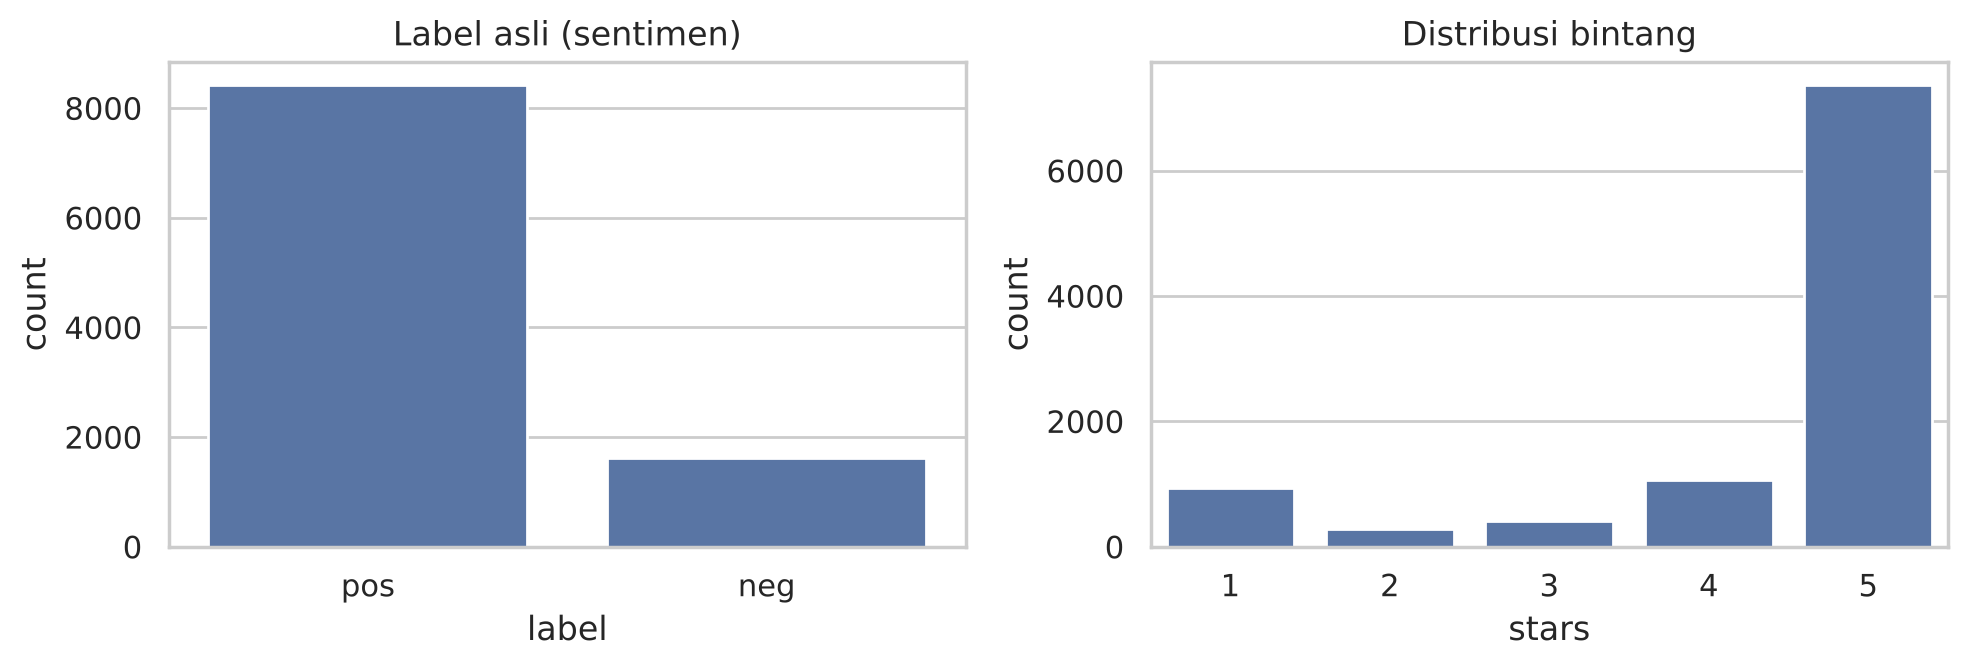

In [3]:
print(orig.dtypes, "\n")
print("Missing values per kolom:\n", orig.isna().sum(), "\n")
print("Distribusi label asli:\n", orig["label"].value_counts(), "\n")
print("Distribusi bintang:\n", orig["stars"].value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(data=orig, x="label", ax=ax[0]); ax[0].set_title("Label asli (sentimen)")
sns.countplot(data=orig, x="stars", ax=ax[1]); ax[1].set_title("Distribusi bintang")
plt.tight_layout(); plt.show()

**Interpretasi.** Label asli sangat condong ke positif dan bintang 5 mendominasi, sehingga banyak ulasan bersifat pujian umum tanpa aspek spesifik. Hal ini menjadi masalah kualitas data utama dan menjelaskan mengapa ada aturan *Ignore* pada guideline.

## 2. Pemeriksaan Kualitas Data Awal

In [4]:
raw = orig["text"].astype(str)
norm_ws = raw.str.replace(r"\s+", " ", regex=True).str.strip()
key = norm_ws.str.lower().str.replace(r"[^\w\s]", "", regex=True)
n_words = norm_ws.str.split().str.len()

quality = pd.Series({
    "Total baris": len(orig),
    "Teks kosong / hanya whitespace": int((norm_ws == "").sum()),
    "Teks tanpa huruf (emoji/simbol/angka saja)": int((~norm_ws.str.contains(r"[A-Za-z]")).sum()),
    "Teks duplikat (setelah normalisasi)": int(key.duplicated().sum()),
    f"Teks < {MIN_WORDS} kata": int((n_words < MIN_WORDS).sum()),
    "Mengandung markup HTML/URL": int(norm_ws.str.contains(r"<[^>]+>|https?://|www\.").sum()),
    "Mengandung karakter encoding rusak (U+FFFD)": int(raw.str.contains(chr(0xFFFD), regex=False).sum()),
})
quality.to_frame("jumlah")

,jumlah
Total baris,10040
Teks kosong / hanya whitespace,0
Teks tanpa huruf (emoji/simbol/angka saja),72
Teks duplikat (setelah normalisasi),2980
Teks < 3 kata,3921
Mengandung markup HTML/URL,0
Mengandung karakter encoding rusak (U+FFFD),0


## 3. Data Cleaning (tercatat dan dapat diulang)

Setiap langkah dicatat jumlah barisnya (*cleaning log*). Kolom `text_raw` menyimpan teks asli dan `id` menunjuk ke baris data asli, sehingga setiap perubahan dapat ditelusuri. Normalisasi hanya mengubah **whitespace** (baris baru dan spasi ganda menjadi satu spasi) dan **tidak** mengubah huruf, ejaan, atau tanda baca, supaya offset span NER tetap valid terhadap `text`.

| Langkah | Alasan |
|---|---|
| Normalisasi whitespace | Ulasan sering memuat baris baru acak yang tidak bermakna |
| Buang teks kosong | Tidak ada informasi |
| Buang teks tanpa huruf | Emoji/simbol/angka saja tidak bermakna untuk dianotasi |
| Buang markup/URL/encoding rusak | Noise teknis (diperiksa; jumlahnya dilaporkan) |
| Deduplikasi | Setiap teks pada dataset akhir harus unik |
| Buang teks < 3 kata | Terlalu pendek untuk memuat aspek ("good", "bagus") |
| Buang teks berbahasa Inggris murni | Kriteria data: berbahasa Indonesia (campuran masih dipertahankan) |

In [5]:
ID_MARK = r"\b(yang|yg|dan|di|ke|dari|untuk|saya|sy|aku|gak|ga|nggak|tidak|tdk|sudah|udah|sdh|banget|bgt|aplikasi|barang|brg|pengiriman|kirim|bayar|belanja|sangat|juga|jg|tapi|tp|dengan|dgn|ini|itu|ada|bisa|bs|lebih|sering|mudah|cepat|cepet|murah|harga|promo|gratis|ongkir|produk|pesanan|saja|aja|nya|sih|kok|lagi|masih|belum|mau|karena|krn|terus|trs|dalam|atau|sekali|bagus|pakai|pake|lama|lambat|kurir)\b"
EN_MARK = r"\b(the|is|are|was|and|very|this|that|it|app|good|great|love|easy|use|not|but|for|with|have|my|so|can|you|to|of|in|on)\b"

df = orig.rename(columns={"text": "text_raw"}).copy()
log = [("Data asli", len(df))]

df["text"] = df["text_raw"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

df = df[df["text"] != ""];                               log.append(("Buang teks kosong", len(df)))
df = df[df["text"].str.contains(r"[A-Za-z]")];           log.append(("Buang teks tanpa huruf", len(df)))
df = df[~(df["text"].str.contains(r"<[^>]+>|https?://|www\.") | df["text"].str.contains(chr(0xFFFD), regex=False))]; log.append(("Buang markup/URL/encoding rusak", len(df)))

df["dedup_key"] = df["text"].str.lower().str.replace(r"[^\w\s]", "", regex=True)
df = df.drop_duplicates("dedup_key", keep="first");       log.append(("Deduplikasi (case/tanda baca diabaikan)", len(df)))

df["n_words"] = df["text"].str.split().str.len()
df = df[df["n_words"] >= MIN_WORDS];                      log.append((f"Buang teks < {MIN_WORDS} kata", len(df)))

low = df["text"].str.lower()
df["_id"] = low.str.count(ID_MARK); df["_en"] = low.str.count(EN_MARK)
df = df[~((df["_id"] == 0) & (df["_en"] > 0))];           log.append(("Buang teks Inggris murni (heuristik)", len(df)))

df = df.drop(columns=["dedup_key", "_id", "_en"]).reset_index(drop=True)
cleaning_log = pd.DataFrame(log, columns=["langkah", "baris_tersisa"])
cleaning_log["dibuang"] = (-cleaning_log["baris_tersisa"].diff()).fillna(0).astype(int)
cleaning_log

,langkah,baris_tersisa,dibuang
0,Data asli,10040,0
1,Buang teks kosong,10040,0
2,Buang teks tanpa huruf,9968,72
3,Buang markup/URL/encoding rusak,9968,0
4,Deduplikasi (case/tanda baca diabaikan),7057,2911
5,Buang teks < 3 kata,5896,1161
6,Buang teks Inggris murni (heuristik),4080,1816


**Catatan.** Deteksi bahasa memakai heuristik kata penanda sederhana, jadi sebagian kecil teks Inggris/campuran bisa lolos atau terbuang. Ini dapat dikoreksi saat anotasi (teks yang tidak relevan di-*Ignore*).

In [6]:
print("Contoh teks yang dipertahankan:")
display(df[["id", "text", "label", "stars"]].sample(8, random_state=SEED))

print("Contoh perubahan whitespace (raw -> clean):")
chg = df[df["text_raw"].astype(str) != df["text"]].head(3)
for _, r in chg.iterrows():
    print(repr(r["text_raw"])); print(" ->", repr(r["text"])); print()

Contoh teks yang dipertahankan:


,id,text,label,stars
33,79,Simpel & oke,pos,5
3316,8093,belanja online yang mudah dan pilihan pembayaran dengan berbagai metode pembayaran sehingga mempermudah transaksi,pos,5
1557,3875,All Service #1.,pos,5
2548,6268,"Mudah,cepat, packing rapih",pos,5
457,1077,"Br pesan perdana udah lama banget, gak bisa tracking. Under expectation lah",neg,2
1444,3602,Oke bgt deh,pos,4
1029,2568,"Belanja aman dan nyaman,highly recommended .",pos,5
3880,9546,"Bagus, cepat dan mudah",pos,5


Contoh perubahan whitespace (raw -> clean):
' Halo\n blibli. Sedikit saran untuk gratis ongkirnya yg minimum 200rb peritem \nDi ubah jadi minum dr total belanja 200rb. Jd bisa beli produk yg sama \ndengn jumlah bnyak. Atau pun bisa beli produk yg berbeda dlam jumlah \nbanyak. Sy harap bisa di terapkan  Makasih'
 -> 'Halo blibli. Sedikit saran untuk gratis ongkirnya yg minimum 200rb peritem Di ubah jadi minum dr total belanja 200rb. Jd bisa beli produk yg sama dengn jumlah bnyak. Atau pun bisa beli produk yg berbeda dlam jumlah banyak. Sy harap bisa di terapkan Makasih'

' So far so good. Respon cepat.'
 -> 'So far so good. Respon cepat.'

' Aplikasi sering not responding di hp saya (asus zenfone t001f)'
 -> 'Aplikasi sering not responding di hp saya (asus zenfone t001f)'



## 4. Penandaan Cue Aspek dan Sampel Anotasi

Banyak ulasan hanya berisi pujian umum. Agar 800 teks yang dianotasi cukup kaya aspek, kami memberi penanda **cue aspek** memakai leksikon kata kunci sederhana per label. Leksikon ini **hanya dipakai untuk memilih sampel**, **bukan sebagai label**: label tetap diberikan manual oleh annotator mengikuti guideline.

In [7]:
CUES = {
    "PENGIRIMAN": r"kurir|kirim|pengiriman|paket|packing|sampai|sampe|ekspedisi|jne|jnt|sicepat|diterima|telat",
    "LAYANAN_PELANGGAN": r"\bcs\b|customer service|costumer|refund|retur|komplain|seller|admin|respon|balas|hubungi|pengembalian",
    "APLIKASI_PERFORMA": r"error|bug|lemot|lambat|\blag\b|loading|force close|crash|hang|nge-?lag|keluar sendiri|not responding|gagal install|gak bisa dibuka",
    "USABILITY": r"tampilan|mudah|susah|ribet|menu|fitur|cari|pencarian|navigasi|simpel|praktis|login|user friendly|bingung",
    "PEMBAYARAN": r"bayar|pembayaran|checkout|transaksi|saldo|e-?wallet|ovo|gopay|dana|virtual account|\bva\b|kartu kredit|cicilan|transfer",
    "PROMO_HARGA": r"promo|diskon|voucher|cashback|harga|mahal|murah|gratis|potongan|hemat",
}
for lab, pat in CUES.items():
    df["cue_" + lab] = df["text"].str.lower().str.contains(pat, regex=True)
cue_cols = ["cue_" + l for l in CUES]
df["n_cues"] = df[cue_cols].sum(axis=1)
df["has_aspect_cue"] = df["n_cues"] > 0

print("Teks bersih:", len(df), "| dengan minimal satu cue aspek:", int(df["has_aspect_cue"].sum()))
df[cue_cols].sum().rename(lambda c: c.replace("cue_", "")).to_frame("jumlah_teks_dengan_cue")

Teks bersih: 4080 | dengan minimal satu cue aspek: 2601


,jumlah_teks_dengan_cue
PENGIRIMAN,609
LAYANAN_PELANGGAN,486
APLIKASI_PERFORMA,260
USABILITY,872
PEMBAYARAN,554
PROMO_HARGA,1062


In [8]:
# Sampel anotasi: dari teks ber-cue, stratifikasi mengikuti proporsi label asli (pos/neg) agar ulasan negatif tidak hilang
pool = df[df["has_aspect_cue"]]
n = min(N_ANNOTATE, len(pool))
frac = n / len(pool)
sample_ids = (pool.groupby("label", group_keys=False)
                  .apply(lambda g: g.sample(frac=frac, random_state=SEED))["id"])
df["in_annotation_sample"] = df["id"].isin(sample_ids)

print("Teks diajukan ke anotasi:", int(df["in_annotation_sample"].sum()))
print(df[df["in_annotation_sample"]]["label"].value_counts().to_string())

Teks diajukan ke anotasi: 1000
label
pos    668
neg    332


In [9]:
final_cols = ["id", "text", "text_raw", "label", "stars", "source_split", "n_words",
              "has_aspect_cue", "n_cues", "in_annotation_sample"]
assert df["text"].is_unique, "Teks tidak unik"
df[final_cols].to_csv(CLEAN, index=False)
print("Disimpan:", CLEAN, df[final_cols].shape)

Disimpan: ../dataset/KelpHHH_dataset_clean.csv (4080, 10)


## 5. EDA Sebelum Anotasi

EDA berikut memakai dataset bersih dan menjadi dasar problem formulation. EDA label multilabel dan NER yang sebenarnya (distribusi label, ko-okurensi, panjang span, imbalance) dilakukan setelah gold dataset hasil adjudication tersedia.

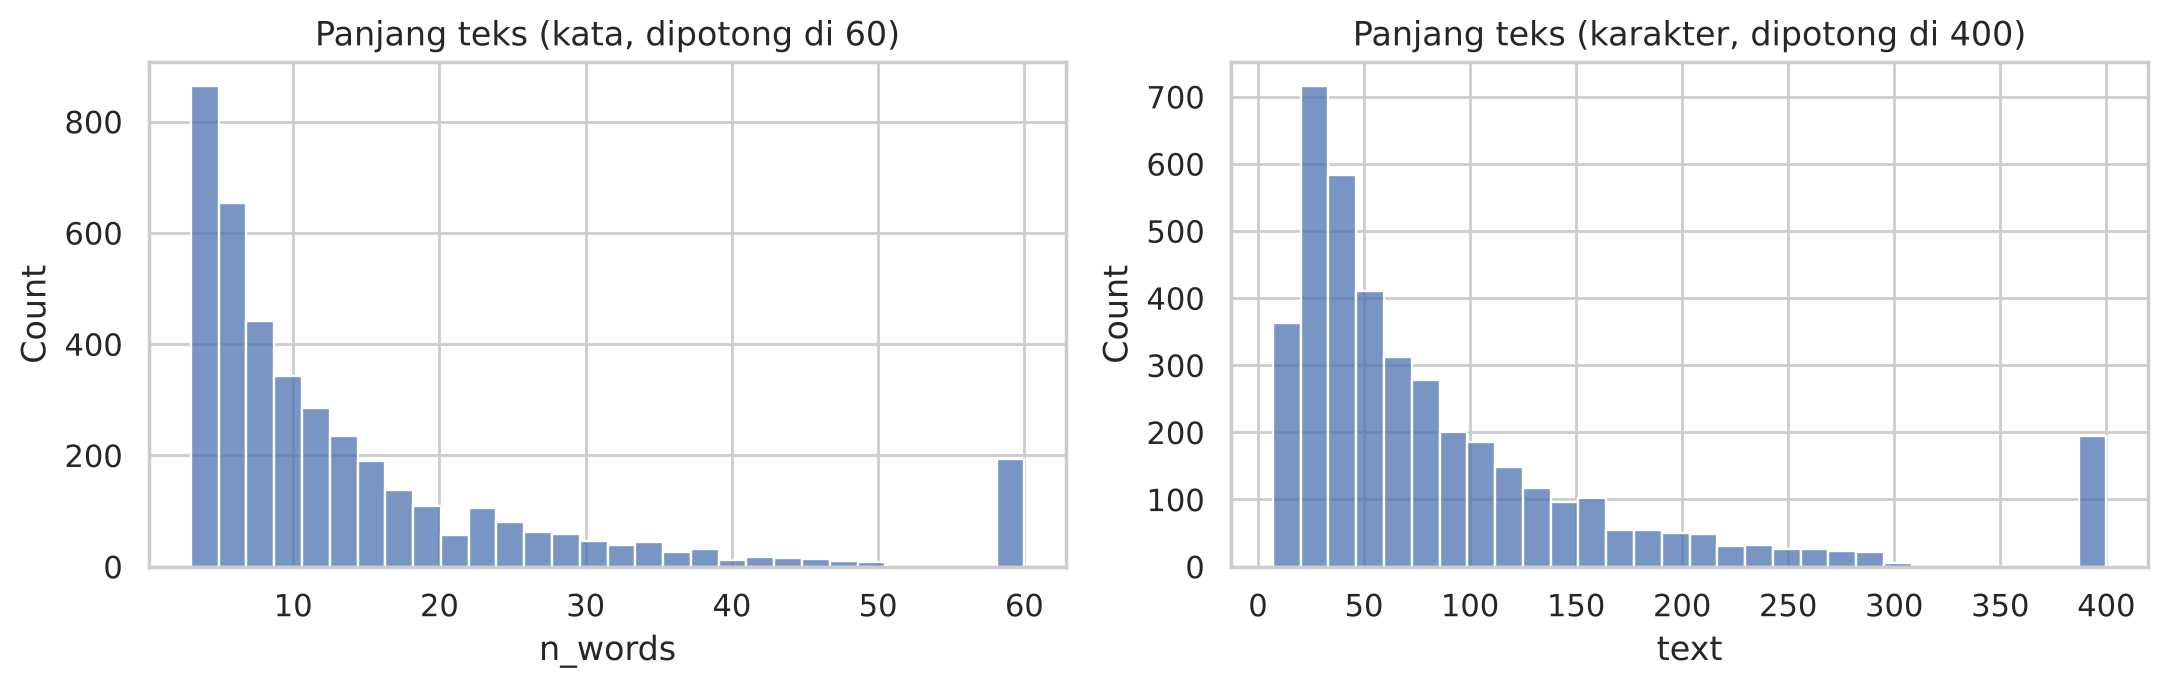

count    4080.0
mean       16.7
std        24.5
min         3.0
25%         5.0
50%         9.0
75%        17.0
max       254.0


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df["n_words"].clip(upper=60), bins=30, ax=ax[0]); ax[0].set_title("Panjang teks (kata, dipotong di 60)")
sns.histplot(df["text"].str.len().clip(upper=400), bins=30, ax=ax[1]); ax[1].set_title("Panjang teks (karakter, dipotong di 400)")
plt.tight_layout(); plt.show()
print(df["n_words"].describe().round(1).to_string())

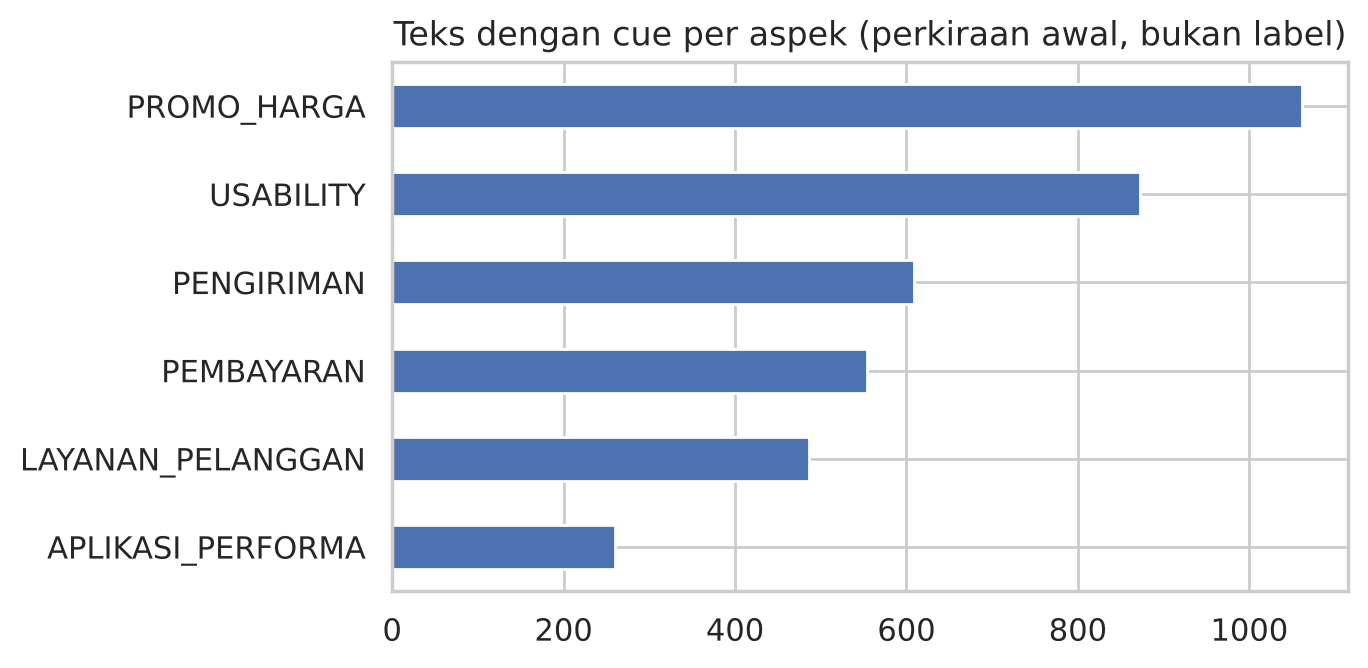

Jumlah cue aspek per teks:
 n_cues
0    1479
1    1686
2     658
3     197
4      51
5       8
6       1


In [11]:
counts = df[cue_cols].sum().rename(lambda c: c.replace("cue_", "")).sort_values()
ax = counts.plot.barh(figsize=(7, 3.5), title="Teks dengan cue per aspek (perkiraan awal, bukan label)")
plt.tight_layout(); plt.show()

print("Jumlah cue aspek per teks:\n", df["n_cues"].value_counts().sort_index().to_string())

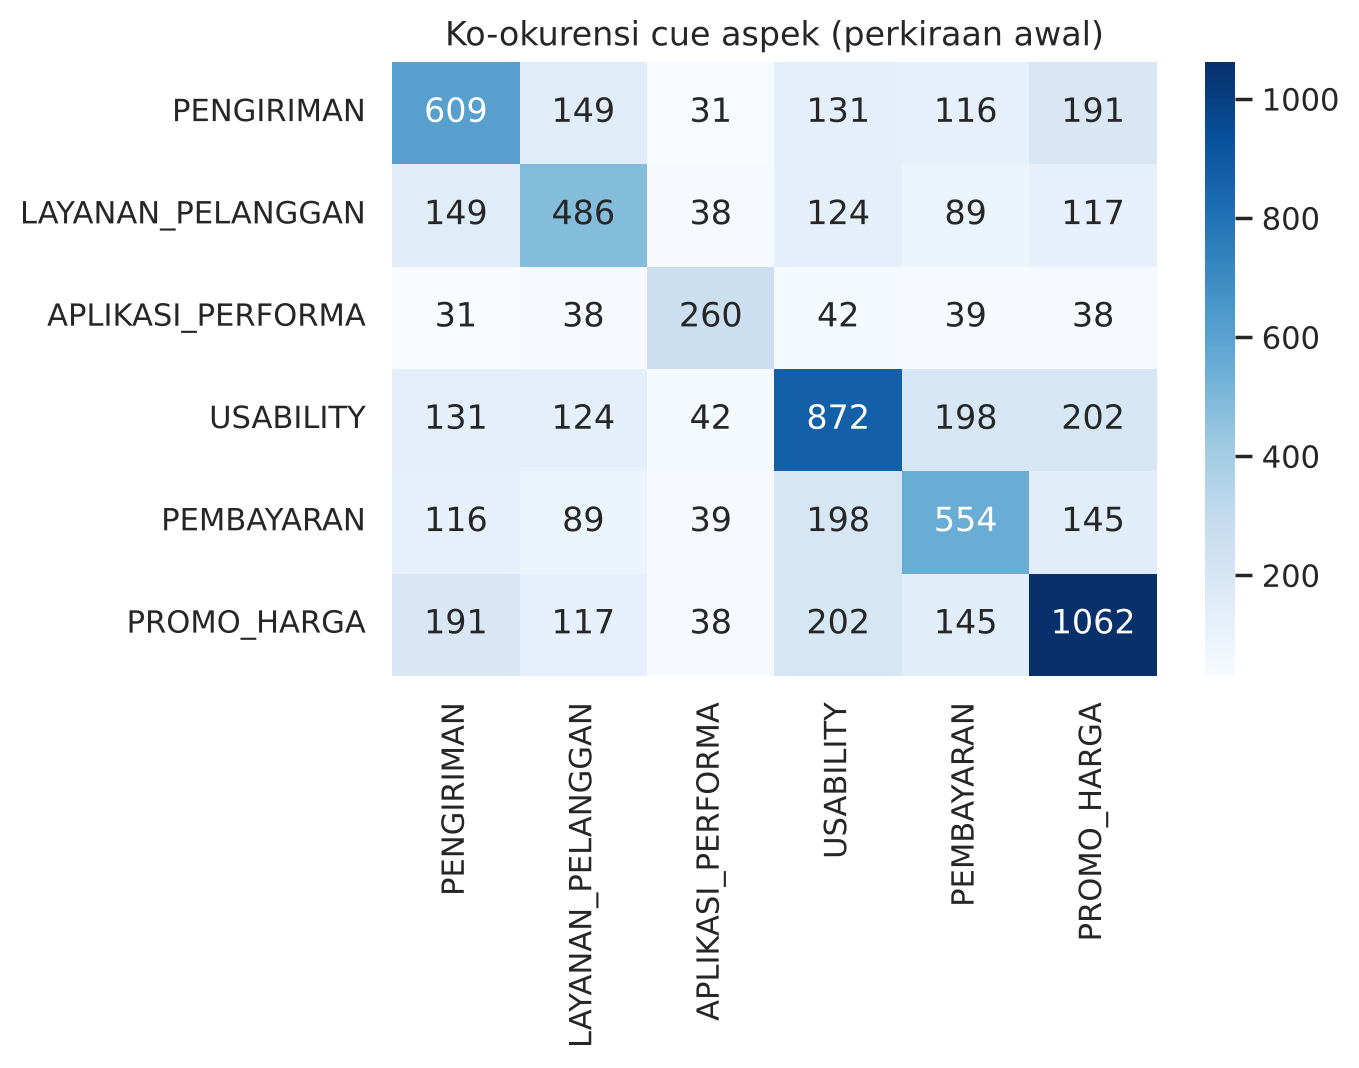

In [12]:
co = df[cue_cols].astype(int).T.dot(df[cue_cols].astype(int))
co.index = co.columns = [c.replace("cue_", "") for c in co.columns]
plt.figure(figsize=(7, 5.5))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues")
plt.title("Ko-okurensi cue aspek (perkiraan awal)")
plt.tight_layout(); plt.show()

**Interpretasi.**
- Banyak ulasan memuat lebih dari satu cue aspek, sehingga masalah ini memang **multilabel** dan bukan single-label.
- Cue PROMO_HARGA dan USABILITY paling banyak, disusul PENGIRIMAN, PEMBAYARAN, dan LAYANAN_PELANGGAN, sedangkan APLIKASI_PERFORMA paling sedikit (sekitar seperempat dari PROMO_HARGA); ini menandakan potensi **label imbalance** yang perlu diperhatikan pada UAS. (Angka persis dilihat pada grafik dan tabel di atas.)
- Kata *ongkir* sengaja tidak menjadi cue PENGIRIMAN, karena "gratis ongkir" termasuk PROMO_HARGA menurut guideline.
- Setiap cue adalah kata/frasa konkret yang dapat di-highlight, sehingga masalah NER (span bukti) **berhubungan langsung** dengan klasifikasi multilabel.

In [13]:
# Contoh evidence dari korpus untuk tiap aspek (bahan justifikasi label dan contoh guideline)
for lab in CUES:
    ex = df[df["cue_" + lab] & (df["n_words"].between(6, 25))].sample(3, random_state=SEED)["text"].tolist()
    print(f"[{lab}]")
    for e in ex: print("  -", e)
    print()

[PENGIRIMAN]
  - Pesanan saya sudah 15 hari belum sampai juga. Ini beneran dikirim gak sih ?
  - barang udh dibayar tinggal nunggu kirim eh, tiba2 di refund... duitnya bisa balik, waktu nya yg gak bisa balik...
  - Saya dari awal sudah nyaman dengan bli bli dari cara bayar sampai pengiriman saya sangat merekomendasikan

[LAYANAN_PELANGGAN]
  - CS nya tidak memberikan solusi/jalan keluar :/
  - Pembayaran listrik saya gagal, dan akan di refund tapi sudah kurang lebih seminggu belum masuk dana nya.. Kecewa saya
  - Sebagai member premier saya sangat terbantu berbelanja di sini dengan pelayanan CS yang memuaskan dan ketersediaan barang yang lengkap.

[APLIKASI_PERFORMA]
  - Sering error ya sekarang Mau bayar via kartu kredit udah coba berkali-kali ga bisa Still processing mulu tulisannya. Udah beberapa kali kejadian kayak gini.
  - Suka banyak diskon tapi setelah update kok malah seperti browser dan lemot banget tolong segera diperbaiki
  - Sering error. Maaf kalo saya review kepada pelay

## 6. EDA Setelah Anotasi (Multilabel dan NER)

Bagian ini membaca gold dataset hasil adjudication. Jika `KelpHHH_dataset_annotation.jsonl` (seluruh data) belum tersedia, notebook memakai `KelpHHH_gold_overlap.jsonl` (200 ulasan overlap yang sudah di-adjudicate) sehingga notebook tetap dapat dijalankan ulang. Hasilnya berubah otomatis setelah file final diletakkan di folder `dataset/`.

In [14]:
import itertools
from collections import Counter
LABELS = list(CUES.keys())
ann_path = DATA / "KelpHHH_dataset_annotation.jsonl"
if not ann_path.exists():
    ann_path = DATA / "KelpHHH_gold_overlap.jsonl"
rows = [json.loads(l) for l in open(ann_path, encoding="utf-8") if l.strip()]
ann = pd.DataFrame(rows)
ann["n_words"] = ann["text"].str.split().str.len()
ann["n_labels"] = ann["labels"].str.len()
ann["n_entities"] = ann["entities"].str.len()
for r in rows:   # validasi offset span terhadap teks
    for e in r["entities"]:
        assert r["text"][e["start"]:e["end"]] == e["text"], (r["id"], e)
print("Sumber:", ann_path.name, "| teks:", len(ann), "| total span:", int(ann["n_entities"].sum()))

Sumber: KelpHHH_dataset_annotation.jsonl | teks: 990 | total span: 2465


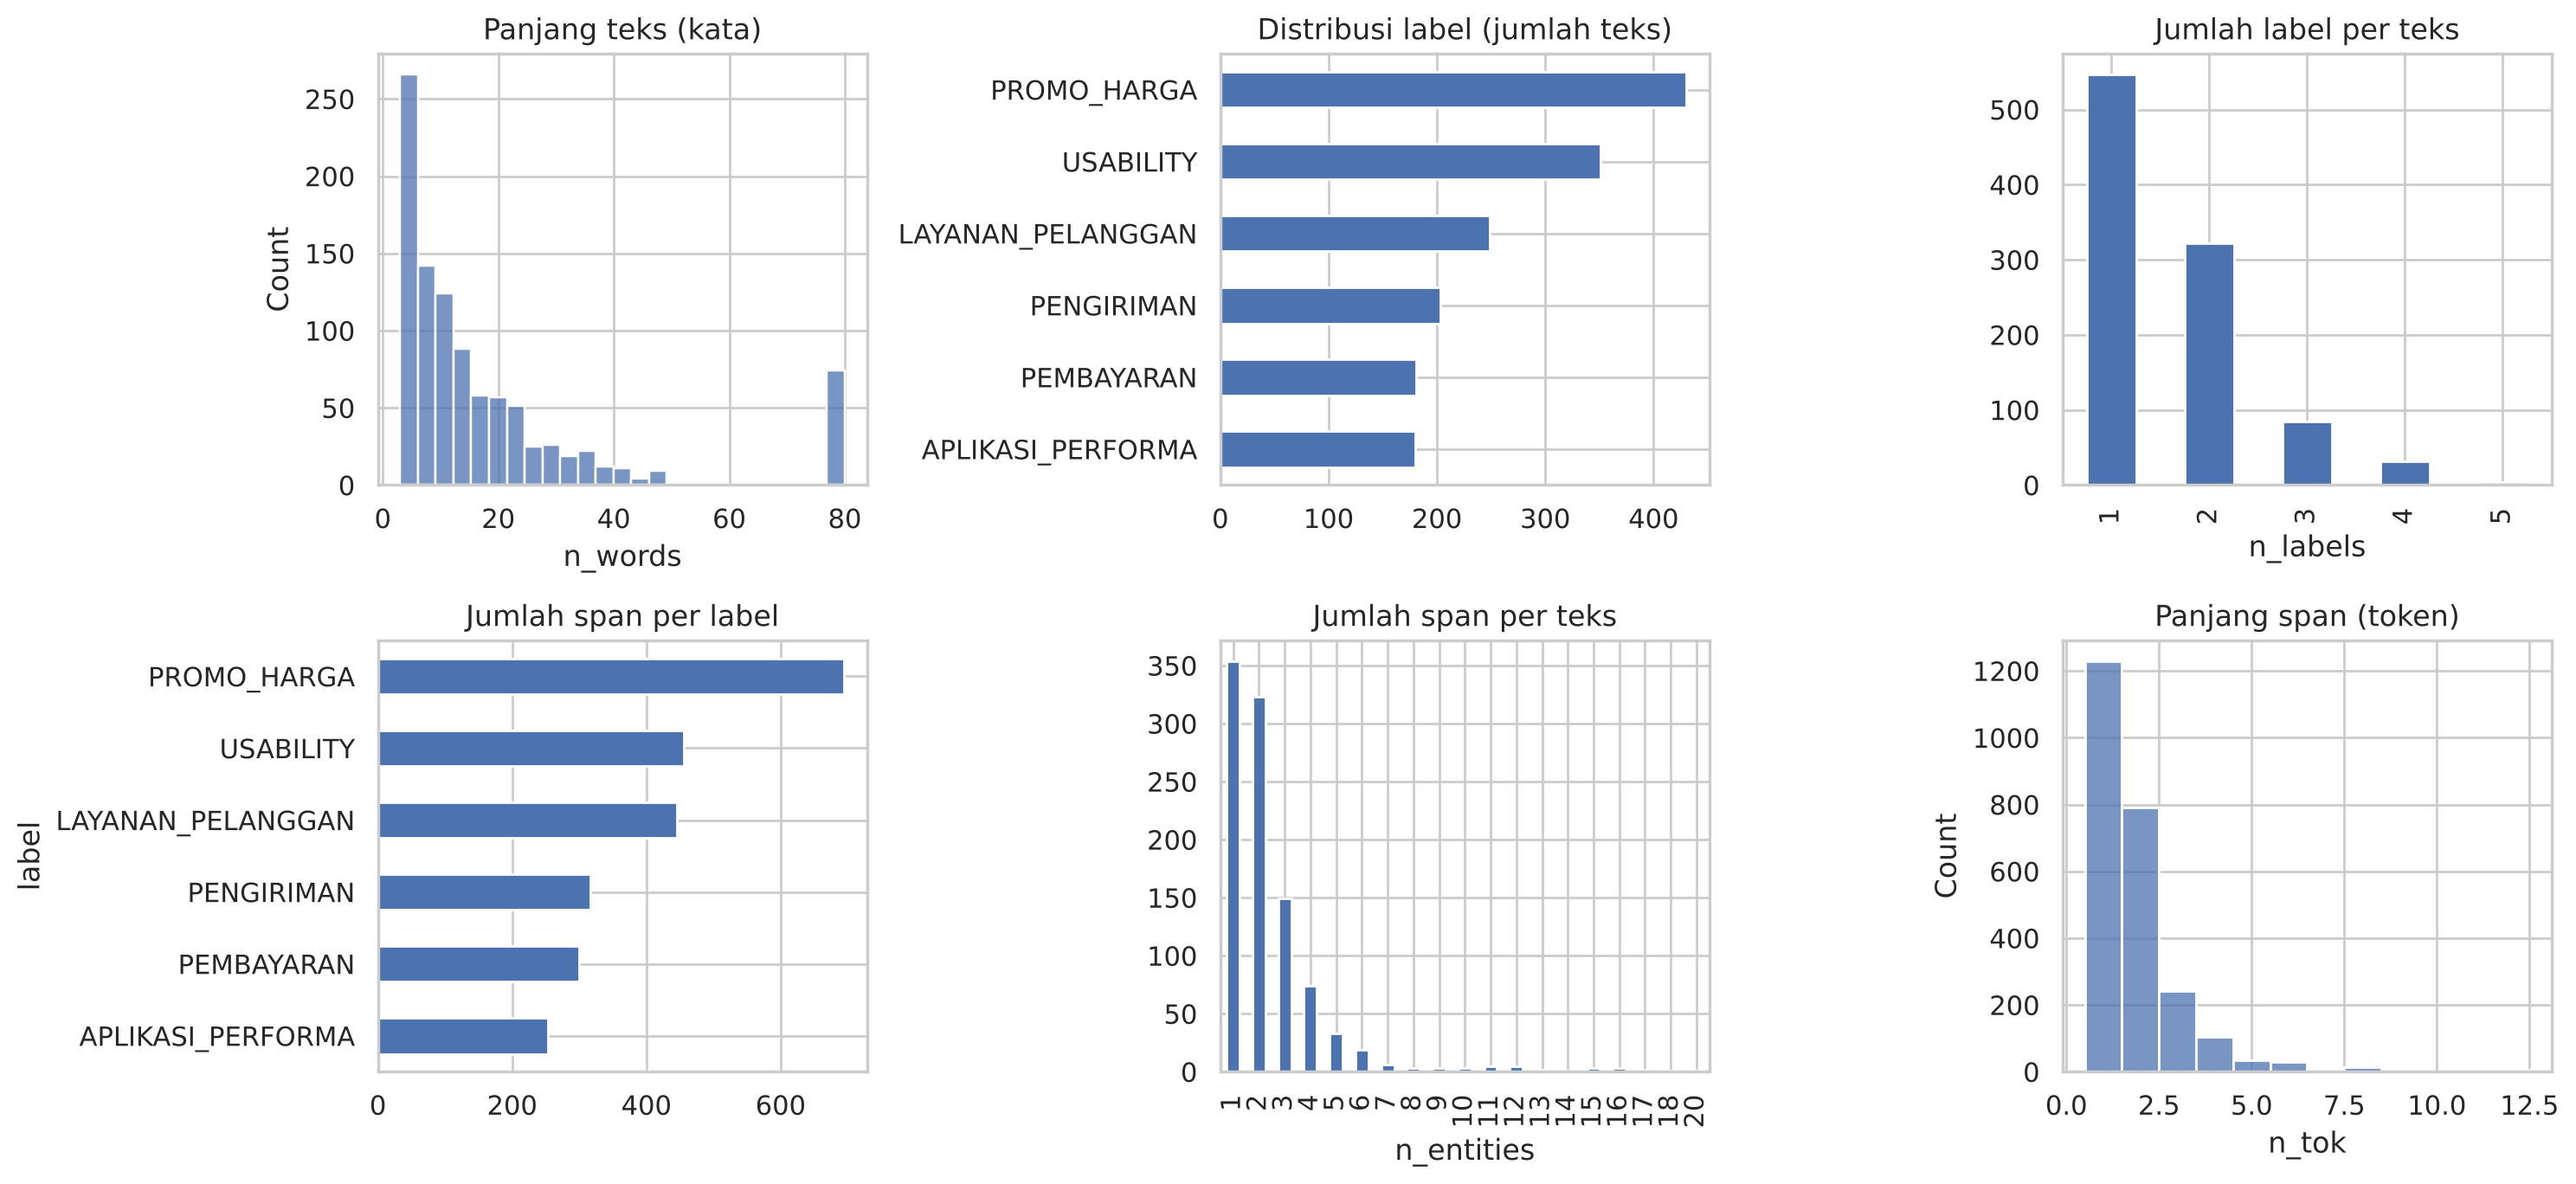

Imbalance ratio label (maks/min): 2.39
Imbalance ratio span  (maks/min): 2.74


In [15]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
sns.histplot(ann["n_words"].clip(upper=80), bins=25, ax=ax[0,0]); ax[0,0].set_title("Panjang teks (kata)")
cnt = pd.Series(Counter(l for ls in ann["labels"] for l in ls)).reindex(LABELS).fillna(0)
cnt.sort_values().plot.barh(ax=ax[0,1], title="Distribusi label (jumlah teks)")
ann["n_labels"].value_counts().sort_index().plot.bar(ax=ax[0,2], title="Jumlah label per teks")
ent = pd.DataFrame([{"label": e["label"], "n_tok": len(e["text"].split()), "text": e["text"].lower()} for es in ann["entities"] for e in es])
ent["label"].value_counts().reindex(LABELS).fillna(0).sort_values().plot.barh(ax=ax[1,0], title="Jumlah span per label")
ann["n_entities"].value_counts().sort_index().plot.bar(ax=ax[1,1], title="Jumlah span per teks")
sns.histplot(ent["n_tok"].clip(upper=12), bins=12, discrete=True, ax=ax[1,2]); ax[1,2].set_title("Panjang span (token)")
plt.tight_layout(); plt.show()
print("Imbalance ratio label (maks/min): %.2f" % (cnt.max() / cnt[cnt > 0].min()))
print("Imbalance ratio span  (maks/min): %.2f" % (ent["label"].value_counts().max() / ent["label"].value_counts().min()))

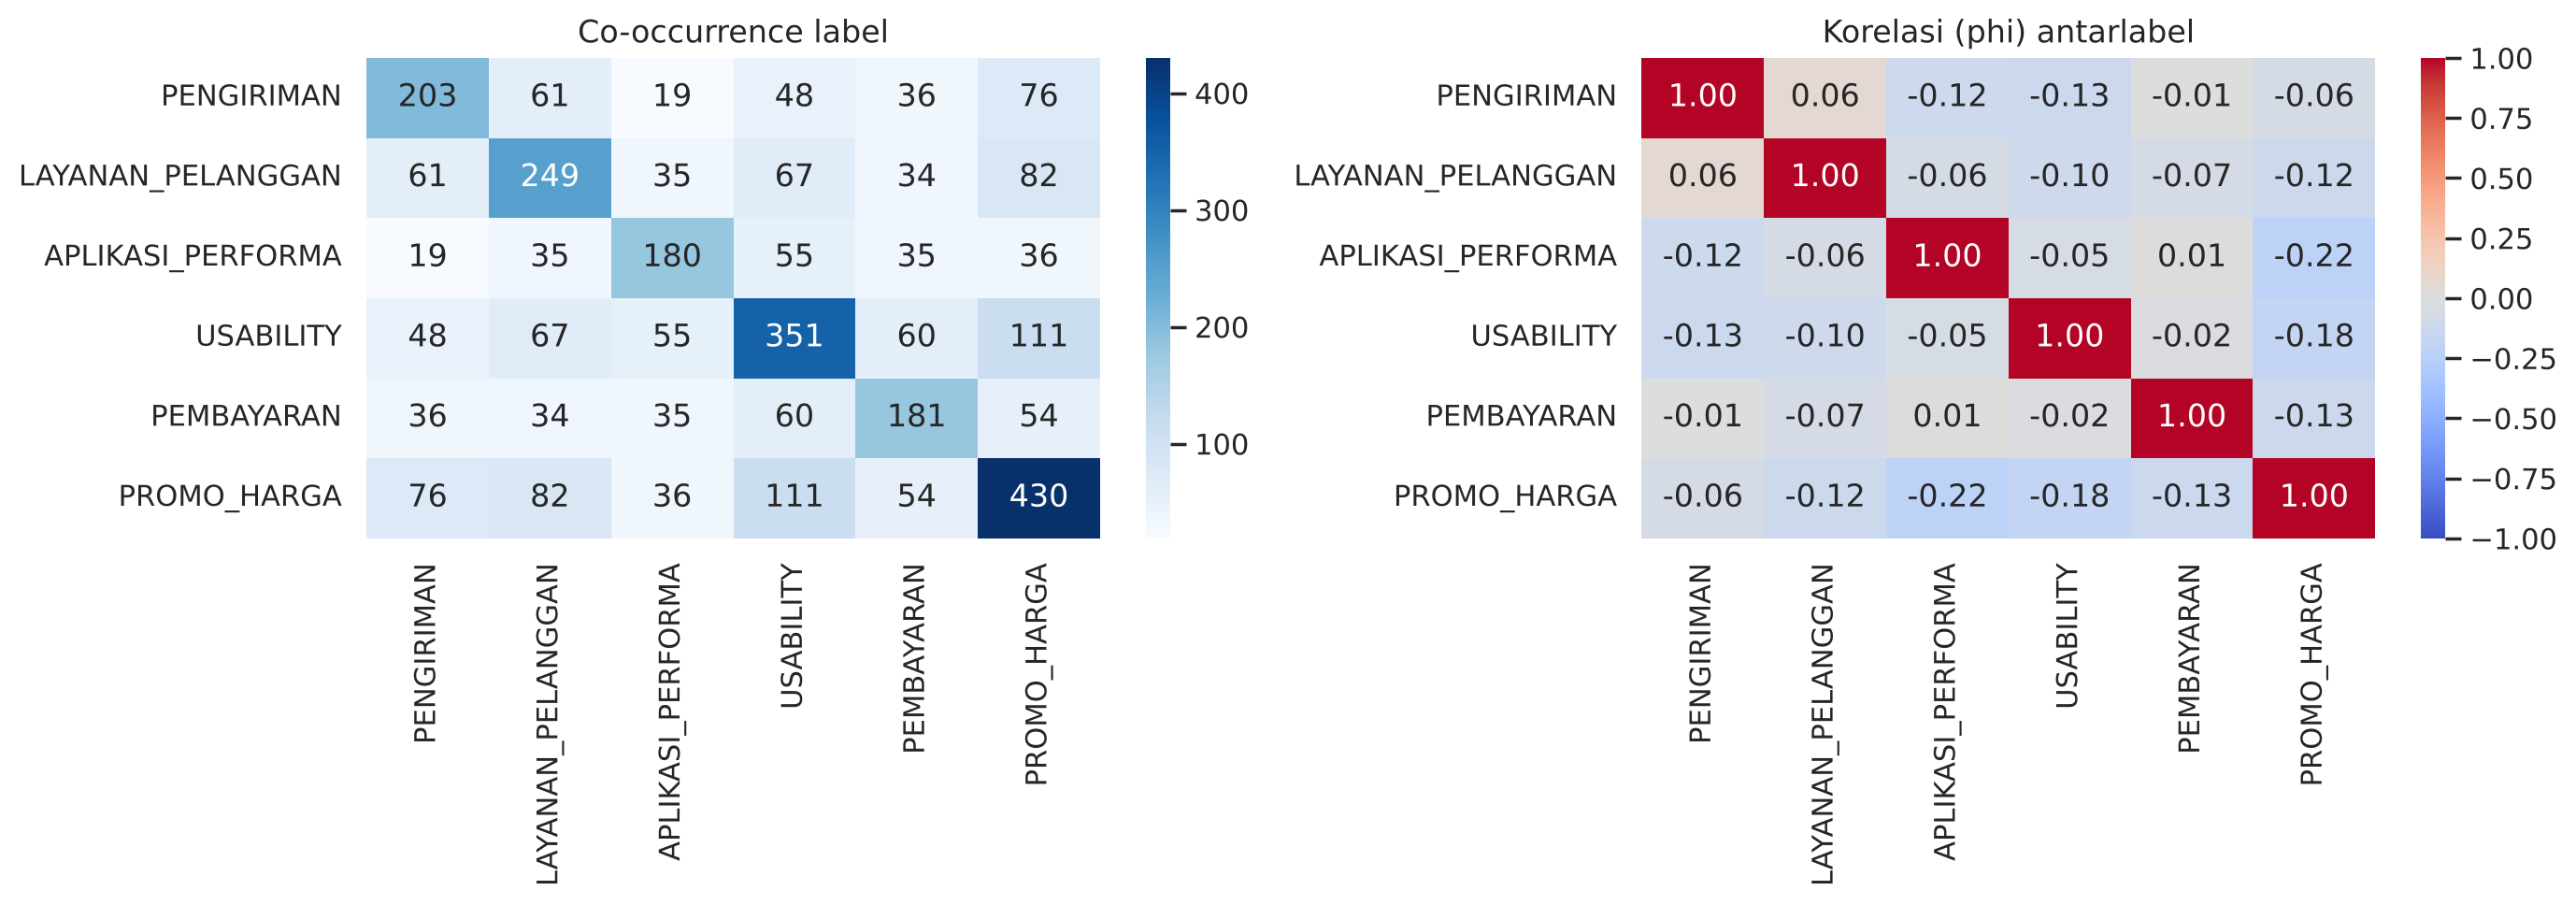

,jumlah
labels,
PROMO_HARGA,188
USABILITY,119
APLIKASI_PERFORMA,68
LAYANAN_PELANGGAN,67
PENGIRIMAN,58
PROMO_HARGA + USABILITY,58
PEMBAYARAN,47
LAYANAN_PELANGGAN + PROMO_HARGA,37
LAYANAN_PELANGGAN + USABILITY,32


In [16]:
B = pd.DataFrame({l: ann["labels"].apply(lambda x, l=l: int(l in x)) for l in LABELS})
co = B.T.dot(B)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", ax=ax[0]); ax[0].set_title("Co-occurrence label")
sns.heatmap(B.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title("Korelasi (phi) antarlabel")
plt.tight_layout(); plt.show()
combo = ann["labels"].apply(lambda x: " + ".join(sorted(x)) or "(kosong)").value_counts().head(10)
combo.to_frame("jumlah")

In [17]:
# Dominasi tag O dan contoh span paling sering (token = pemisah spasi)
tot_tok = int(ann["n_words"].sum()); span_tok = int(ent["n_tok"].sum())
print("Token dalam span: %d dari %d (%.1f%%); tag O sekitar %.1f%%" % (span_tok, tot_tok, 100*span_tok/tot_tok, 100*(1-span_tok/tot_tok)))
top = ent.groupby(["label", "text"]).size().reset_index(name="n").sort_values("n", ascending=False)
for lab in LABELS:
    print(lab, "->", ", ".join(f"{t} ({n})" for t, n in top[top.label == lab].head(5)[["text", "n"]].values))

Token dalam span: 4606 dari 21128 (21.8%); tag O sekitar 78.2%
PENGIRIMAN -> pengiriman (51), pengiriman cepat (17), kirim (12), dikirim (10), sampe (10)
LAYANAN_PELANGGAN -> cs (22), refund (21), pelayanan (18), penjual (17), seller (16)
APLIKASI_PERFORMA -> error (15), lancar (11), bug (7), lemot (7), crash (6)
USABILITY -> mudah (102), simple (15), user friendly (14), praktis (12), memudahkan (12)
PEMBAYARAN -> pembayaran (68), bayar (24), gopay (15), cicilan (13), kartu kredit (12)
PROMO_HARGA -> promo (71), harga (43), free ongkir (38), banyak promo (35), murah (29)


**Interpretasi.**
- Distribusi label tidak terlalu timpang, tetapi APLIKASI_PERFORMA dan PEMBAYARAN lebih jarang daripada PROMO_HARGA dan USABILITY. Pada pemodelan (UAS) kelas ini perlu dipantau dengan metrik per label (bukan hanya akurasi) dan bila perlu pembobotan kelas.
- Rata-rata lebih dari satu label per teks dan ada pasangan label yang sering muncul bersama (mis. PROMO_HARGA dan PENGIRIMAN lewat "gratis ongkir"), sehingga multilabel memang diperlukan.
- Tag O mendominasi level token karena span hanya mencakup frasa bukti; metrik NER perlu berbasis entity (F1 entity) bukan akurasi token.
- Karena label span sama dengan label dokumen, setiap prediksi dokumen dapat diperiksa dengan bukti span-nya.

## 7. Ringkasan
Dataset bersih tersimpan di `../dataset/KelpHHH_dataset_clean.csv`. Kolom `in_annotation_sample` menandai teks yang diajukan ke Prodigy. Hasil anotasi dan adjudication akan disimpan di `KelpHHH_dataset_annotation.jsonl` sesuai format pada guideline.